# Validation notebook

Checks the formulas against reference values and shows how sensitive IOL power is to biometry errors.

**Learning tool only. Not for clinical use. Checked against hand calculations and the published equations, not against independent reference values or clinical outcomes.**

In [1]:
import sys

sys.path.insert(0, '../src')
import matplotlib.pyplot as plt

from iol_calc import srk1_power, srkt_details, srkt_power, vergence_power

## 1. Reference comparison

Fill `reference_power` with values from a published worked example or an online SRK/T calculator, using the same AL, K and A-constant, and record the source for each row.

**Status:** no reference value has been sourced yet, so every row is `None`. Values are never estimated; a row is filled only when it has a source that can be checked.

In [2]:
cases = [
    # (label, AL mm, K D, A-constant, reference SRK/T power or None, source)
    ("short eye",   21.0, 45.0, 118.4, None, "not yet sourced"),
    ("average eye", 23.5, 44.0, 118.4, None, "not yet sourced"),
    ("long eye",    26.0, 43.0, 118.4, None, "not yet sourced"),
    ("very long",   29.0, 42.0, 118.4, None, "not yet sourced"),
]
print(f"{'case':12} {'SRK/T':>7} {'SRK I':>7} {'ref':>7} {'diff':>6}")
for label, al, k, a, ref, _src in cases:
    p = srkt_power(al, k, a)
    s1 = srk1_power(al, k, a)
    diff = '' if ref is None else f"{p - ref:+.2f}"
    print(f"{label:12} {p:7.2f} {s1:7.2f} {'' if ref is None else f'{ref:7.2f}':>7} {diff:>6}")

case           SRK/T   SRK I     ref   diff
short eye      27.45   25.40               
average eye    20.04   20.05               
long eye       13.61   14.70               
very long       7.04    8.10               


## 2. Sensitivity to biometry error

How much the SRK/T power changes for a given error in axial length or keratometry, for an average eye.

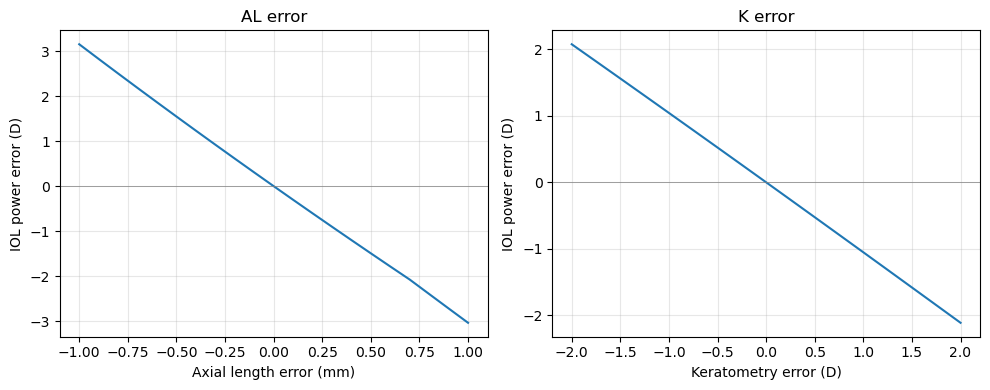

About 3.04 D of IOL power per mm of AL error


In [3]:
al0, k0, a0 = 23.5, 44.0, 118.4
p0 = srkt_power(al0, k0, a0)
al_err = [x / 10 for x in range(-10, 11)]
k_err = [x / 4 for x in range(-8, 9)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(al_err, [srkt_power(al0 + e, k0, a0) - p0 for e in al_err])
axes[0].set(xlabel='Axial length error (mm)', ylabel='IOL power error (D)', title='AL error')
axes[1].plot(k_err, [srkt_power(al0, k0 + e, a0) - p0 for e in k_err])
axes[1].set(xlabel='Keratometry error (D)', ylabel='IOL power error (D)', title='K error')
for ax in axes:
    ax.axhline(0, lw=0.5, color='grey')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
dp_dal = srkt_power(al0 + 0.1, k0, a0) - srkt_power(al0 - 0.1, k0, a0)
print(f"About {abs(dp_dal) * 5:.2f} D of IOL power per mm of AL error")

## 3. Formula comparison across axial lengths

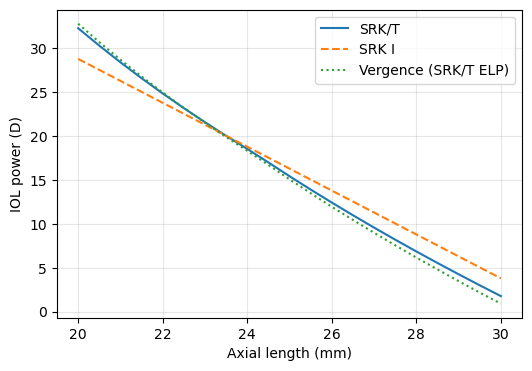

In [4]:
als = [x / 2 for x in range(40, 61)]
plt.figure(figsize=(6, 4))
plt.plot(als, [srkt_power(al, 44.0, 118.4) for al in als], label='SRK/T')
plt.plot(als, [srk1_power(al, 44.0, 118.4) for al in als], label='SRK I', ls='--')
vergence_srkt_elp = [vergence_power(al, 44.0, srkt_details(al, 44.0, 118.4)['elp']) for al in als]
plt.plot(als, vergence_srkt_elp, label='Vergence (SRK/T ELP)', ls=':')
plt.xlabel('Axial length (mm)')
plt.ylabel('IOL power (D)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Limitations

- No patient outcome data, so no mean absolute error or percent within 0.5 D.
- SRK I is a regression formula and is known to be inaccurate in short and long eyes; it is here for teaching.
- Not for clinical use.